# MLE in Naive Bayes

Accuracy: 0.77


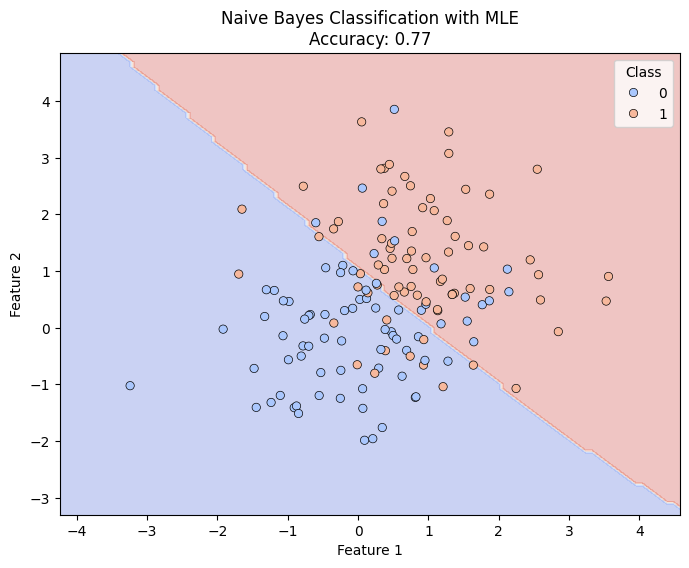

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Generate synthetic sound event data
np.random.seed(42)
n_samples = 500
n_features = 2  # MFCC features
n_classes = 2  # Two different sound events

# Simulate MFCC feature vectors for different sound classes
X = np.vstack([
    np.random.normal(loc=i, scale=1, size=(n_samples // n_classes, n_features))
    for i in range(n_classes)
])
y = np.hstack([
    np.full(n_samples // n_classes, i)
    for i in range(n_classes)
])

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Compute MLE estimates for mean and variance per class
class_0 = X_train[y_train == 0]
class_1 = X_train[y_train == 1]

# Maximum Likelihood Estimation (MLE) for mean and variance
mu_0 = np.mean(class_0, axis=0)
sigma_0 = np.var(class_0, axis=0, ddof=0)  # MLE variance estimate
mu_1 = np.mean(class_1, axis=0)
sigma_1 = np.var(class_1, axis=0, ddof=0)  # MLE variance estimate

# Compute class priors using MLE
prior_0 = len(class_0) / len(X_train)
prior_1 = len(class_1) / len(X_train)

# Define function for Gaussian likelihood using MLE estimates
def gaussian_likelihood(x, mu, sigma):
    return (1 / np.sqrt(2 * np.pi * sigma)) * np.exp(-((x - mu) ** 2) / (2 * sigma))

# Predict function using Naive Bayes with MLE
def predict(X):
    likelihood_0 = np.prod(gaussian_likelihood(X, mu_0, sigma_0), axis=1) * prior_0
    likelihood_1 = np.prod(gaussian_likelihood(X, mu_1, sigma_1), axis=1) * prior_1
    return (likelihood_1 > likelihood_0).astype(int)

# Predict on the test set
y_pred = predict(X_test)

# Compute accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Plot decision boundary
if n_features<=2:
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 100),
                        np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 100))
    Z = predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_test, palette='coolwarm', edgecolor='k')
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(f"Naive Bayes Classification with MLE\nAccuracy: {accuracy:.2f}")
    plt.legend(title="Class")
    plt.show()


# MAP vs MLE

True μ: 5
MLE Estimate: 5.9740
MAP Estimate: 4.9783 (Regularized towards 0)


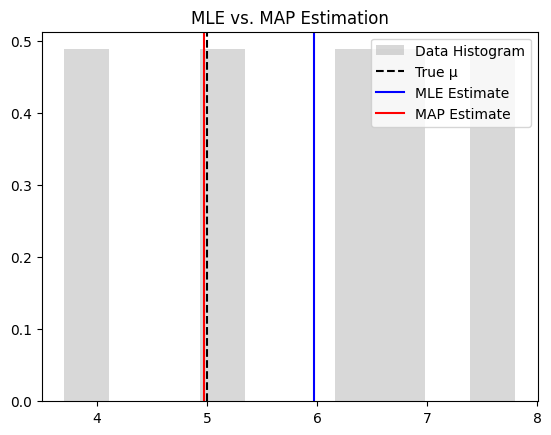

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Generate synthetic data (true parameters)
true_mu = 5
sigma = 2
N = 5  # Small dataset to show the advantage of MAP
data = np.random.normal(true_mu, sigma, N)

# MLE estimation
mu_mle = np.mean(data)

# MAP estimation with Gaussian prior
mu_0 = 0  # Prior mean
tau2 = 1  # Prior variance (strong regularization if small)
mu_map = (N * mu_mle + mu_0 / tau2) / (N + 1 / tau2)

# Print results
print(f"True μ: {true_mu}")
print(f"MLE Estimate: {mu_mle:.4f}")
print(f"MAP Estimate: {mu_map:.4f} (Regularized towards {mu_0})")

# Visualization
x_vals = np.linspace(-2, 10, 100)
plt.hist(data, bins=10, alpha=0.3, label="Data Histogram", color="gray", density=True)
plt.axvline(true_mu, color='black', linestyle='--', label="True μ")
plt.axvline(mu_mle, color='blue', linestyle='-', label="MLE Estimate")
plt.axvline(mu_map, color='red', linestyle='-', label="MAP Estimate")
plt.legend()
plt.title("MLE vs. MAP Estimation")
plt.show()

# GMM using EM

Sound Event Classification Accuracy: 0.35


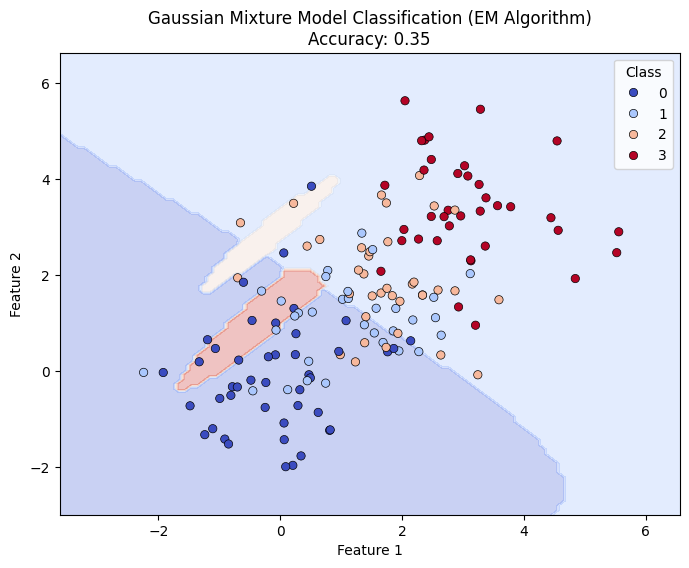

In [49]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Generate synthetic sound event data
np.random.seed(42)
n_samples = 500
n_features = 2  # MFCC features
n_classes = 4  # Three different sound events

# Simulate MFCC feature vectors for different sound classes
X = np.vstack([
    np.random.normal(loc=i, scale=1, size=(n_samples // n_classes, n_features))
    for i in range(n_classes)
])
y = np.hstack([
    np.full(n_samples // n_classes, i)
    for i in range(n_classes)
])

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize parameters for Gaussian Mixture Model (GMM) for each class
K = n_classes  # Number of clusters (one per class)
n_train_samples, n_features = X_train.shape

# Randomly initialize means, covariances, and priors
mu = np.random.rand(K, n_features) * (X_train.max(axis=0) - X_train.min(axis=0)) + X_train.min(axis=0)
sigma = np.array([np.eye(n_features) for _ in range(K)])  # Identity covariance matrices
priors = np.ones(K) / K  # Equal priors

# Expectation-Maximization (EM) Algorithm
max_iter = 100
for iteration in range(max_iter):
    # E-step: Compute responsibilities (posterior probabilities)
    responsibilities = np.zeros((n_train_samples, K))
    for k in range(K):
        diff = X_train - mu[k]
        sigma_inv = np.linalg.inv(sigma[k])
        sigma_det = np.linalg.det(sigma[k])
        norm_const = 1 / (np.sqrt((2 * np.pi) ** n_features * sigma_det))
        exponent = -0.5 * np.sum(diff @ sigma_inv * diff, axis=1)
        responsibilities[:, k] = priors[k] * norm_const * np.exp(exponent)
    responsibilities /= responsibilities.sum(axis=1, keepdims=True)

    # M-step: Update parameters
    Nk = responsibilities.sum(axis=0)
    priors = Nk / n_train_samples
    mu = (responsibilities.T @ X_train) / Nk[:, None]
    for k in range(K):
        diff = X_train - mu[k]
        sigma[k] = (responsibilities[:, k][:, None] * diff).T @ diff / Nk[k]

# Predict function using trained GMM parameters
def predict(X):
    likelihoods = np.zeros((X.shape[0], K))
    for k in range(K):
        diff = X - mu[k]
        sigma_inv = np.linalg.inv(sigma[k])
        sigma_det = np.linalg.det(sigma[k])
        norm_const = 1 / (np.sqrt((2 * np.pi) ** n_features * sigma_det))
        exponent = -0.5 * np.sum(diff @ sigma_inv * diff, axis=1)
        likelihoods[:, k] = priors[k] * norm_const * np.exp(exponent)
    return np.argmax(likelihoods, axis=1)

# Predict on the test set
y_pred = predict(X_test)

# Compute accuracy
accuracy = accuracy_score(y_test, y_pred)

# Print accuracy
print(f"Sound Event Classification Accuracy: {accuracy:.2f}")

# Plot decision boundary
xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 100),
                     np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 100))
Z = predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_test, palette='coolwarm', edgecolor='k')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title(f"Gaussian Mixture Model Classification (EM Algorithm)\nAccuracy: {accuracy:.2f}")
plt.legend(title="Class")
plt.show()

